# TODO:
1. generate data, 
2. do pyschometric analysis
3. decoding for stimulus, block and choice
4. check if there is any true separation
5. run ablation studies

In [178]:
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
from scipy import stats
from modularRNN.analysis import (
    load_and_pool_sessions,
    decode_module_specificity,
    plot_rt_distributions,
    plot_rt_vs_contrast,
    plot_module_specificity,
    add_outcome_and_congruency_columns,
)
from modularRNN.generate_data import run_and_save_multi_session, load_checkpoint
from modularRNN.generators import SessionPlanGenerator
from modularRNN.conf.config import Config
import torch
from glob import glob
from matplotlib import pyplot as plt
import seaborn as sns
import psychofit as psy
from modularRNN.plotting import (
    plot_psychometric,
    plot_population_psychometric_by_block_pooled,
    pretty_plot,
    reaction_time_plots,
)
import warnings

In [ ]:
warnings.filterwarnings("ignore")

In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
fallback = (
    "/Users/dkundu/Documents/phd/modular-rnn/model/checkpoints/scneods2/config.yaml"
)
ckpt_path = (
    "/Users/dkundu/Documents/phd/modular-rnn/model/checkpoints/scneods2/ckpt_19000.pt"
)
model_name = ckpt_path.rsplit("/")[-2]
device = "cpu"
model, train_cfg = load_checkpoint(ckpt_path, device, fallback_config_path=fallback)

Loaded checkpoint from step 19000


/Users/dkundu/Documents/phd/modular-rnn/modularRNN/generate_data.py:14: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ckpt = torch.load(ckpt_path, map_location=device)


In [4]:
# we already have the data, so no more generation
path = glob("../data/multi_session_no_action_kernel/*")

In [5]:
meta_df, hidden_visual, hidden_motor = load_and_pool_sessions(path)
trace_len = meta_df["trace_len"].values

In [8]:
meta_df = add_outcome_and_congruency_columns(meta_df)

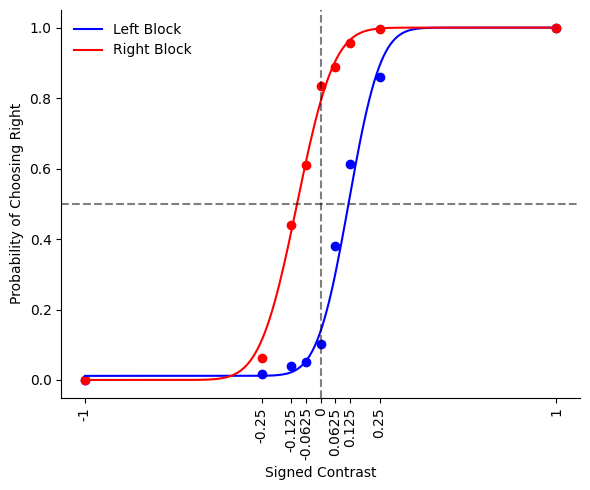

In [27]:
params, fig = plot_population_psychometric_by_block_pooled(meta_df)

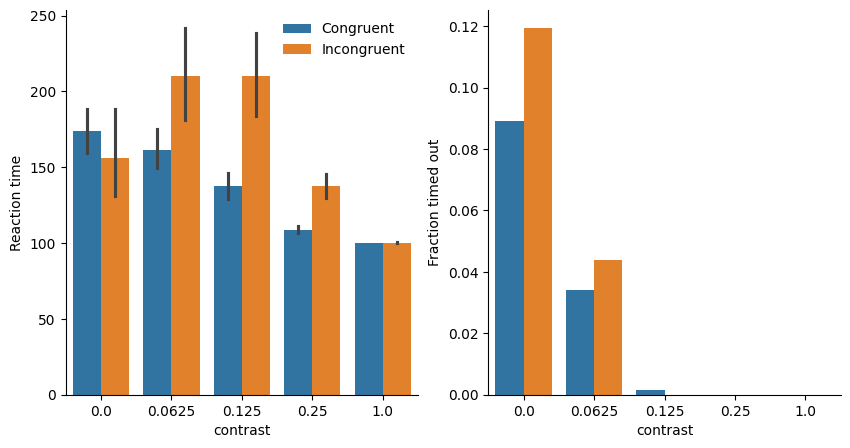

In [179]:
reaction_time_plots(meta_df, train_cfg.env.T_max)

In [ ]:
decode_results = decode_module_specificity(
    hidden_visual,
    hidden_motor,
    meta_df,
    trace_len,
    n_shuffles=100,
    epoch_fracs=(0, 0.2, 0.5, 0.8, 1),
)

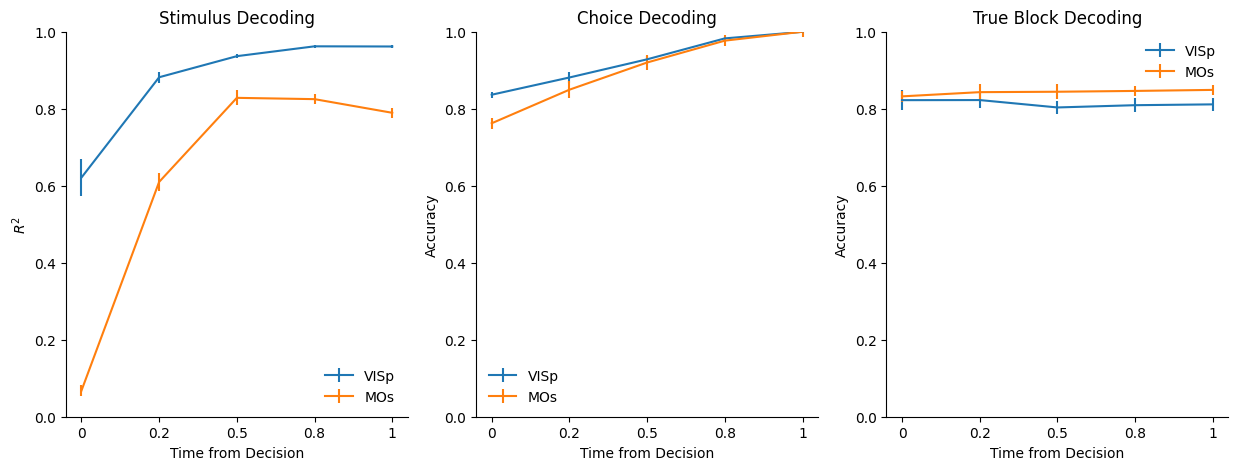

In [181]:
pretty_plot(decode_results)

In [183]:
def repeat_rate_by_contrast(meta_df):
    d = meta_df.copy()
    d["has_prev_choice"] = d["has_prev_choice"].astype(bool)
    d["repeated"] = d["choice"] == d["prev_model_choice"]
    return d[d["has_prev_choice"]].groupby("contrast")["repeated"].mean()


print(repeat_rate_by_contrast(meta_df))

contrast
0.0000    0.907104
0.0625    0.847147
0.1250    0.767492
0.2500    0.695925
1.0000    0.638918
Name: repeated, dtype: float64


In [185]:
d = meta_df[(meta_df["contrast"] == 0.0) & (meta_df["committed"])]
d.groupby("congruent")["correct"].mean()

congruent
False    0.318519
True     0.858439
Name: correct, dtype: float64

In [190]:
def repeat_rate_by_contrast_and_congruency(meta_df):
    d = meta_df.copy()
    d["has_prev_choice"] = d["has_prev_choice"].astype(bool)
    d["repeated"] = d["choice"] == d["prev_model_choice"]

    is_biased = d["block_bias"] != 0.5
    block_right = d["block_bias"] > 0.5
    stim_right = d["stim_side"] > 0
    d["congruent"] = (block_right == stim_right) & is_biased
    d["incongruent"] = (~d["congruent"]) & is_biased
    d["congruency"] = np.where(
        d["congruent"], "congruent", np.where(d["incongruent"], "incongruent", None)
    )

    d = d[d["has_prev_choice"] & d["congruency"].notna()]

    return (
        d.groupby(["contrast", "congruency"])["repeated"]
        .agg(["mean", "size"])
        .rename(columns={"mean": "repeat_rate", "size": "n"})
    )


def plot_repeat_rate_by_contrast_and_congruency(result_df):
    result_df = result_df.reset_index()
    fig, ax = plt.subplots(figsize=(6, 4.5))
    colors = {"congruent": "tab:blue", "incongruent": "tab:orange"}

    for cond, color in colors.items():
        sub = result_df[result_df["congruency"] == cond].sort_values("contrast")
        ax.plot(
            sub["contrast"], sub["repeat_rate"], marker="o", color=color, label=cond
        )
    ax.set_xlabel("contrast")
    ax.set_ylabel("repeat rate")
    ax.set_ylim(0, 1.05)
    ax.legend(fontsize=9)
    fig.tight_layout()
    ax.set_title("Repeats")
    ax.set_xticks(
        result_df["contrast"].unique(),
        labels=result_df["contrast"].unique(),
        rotation=90,
    )
    sns.despine()
    return fig

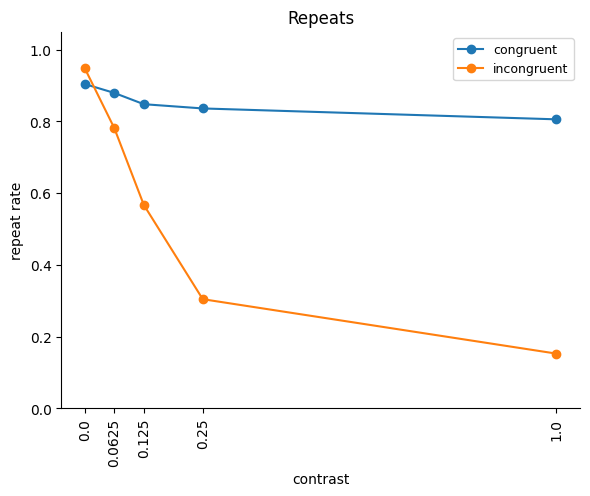

In [191]:
result_df = repeat_rate_by_contrast_and_congruency(meta_df)
fig = plot_repeat_rate_by_contrast_and_congruency(result_df)